<a href="https://colab.research.google.com/github/Alafiade/Computational-Pathology/blob/main/Attention_Base_Multiple_Instance_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploring Attention-Based Multiple Instance Learning (ABMIL)

### Investigating the Effect of Training Data Scarcity on Model Generalization

**Objective**

To investigate how the availability of labelled training data influences the generalization performance of an Attention-Based Multiple Instance Learning (ABMIL) model.

**Experimental Overview**

Using an MNIST-based bag classification dataset, four experiments were conducted with varying training dataset sizes:

- Experiment A: 200 training bags
- Experiment B: 100 training bags
- Experiment C: 50 training bags
- Experiment D: 25 training bags

Each experiment was evaluated using a fixed test dataset of 200 bags.

**Evaluation Metrics**
- Training and test loss
- Training and test accuracy

**Hypothesis**

Reducing the number of training bags will negatively affect the model's ability to generalize to unseen data.

**Key Finding**

Test accuracy decreased from 95% to 68% as the training dataset was reduced from 200 to 25 bags, supporting the hypothesis that training data scarcity can negatively affect ABMIL generalization in this experimental setting.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import torch.utils.data as data_utils
from torchvision import datasets, transforms

In [2]:
class MnistBags(data_utils.Dataset):
    def __init__(self, target_number=9, mean_bag_length=10, var_bag_length=1, num_bag=1000, seed=7, train=True):
        self.target_number = target_number
        self.mean_bag_length = mean_bag_length
        self.var_bag_length = var_bag_length
        self.num_bag = num_bag
        self.seed = seed
        self.train = train

        self.r = np.random.RandomState(seed)

        self.num_in_train = 60000

        self.num_in_test = 10000

        if self.train:
            self.train_bags_list, self.train_labels_list = self._form_bags()
        else:
            self.test_bags_list, self.test_labels_list = self._form_bags()

    def _form_bags(self):
        if self.train:
            train_loader = data_utils.DataLoader(datasets.MNIST('../datasets',
                                                                train=True,
                                                                download=True,
                                                                transform=transforms.Compose([
                                                                         transforms.ToTensor(),
                                                                         transforms.Normalize((0.1307,), (0.3081,))])),
                                                 batch_size=self.num_in_train,
                                                 shuffle=False)

            bags_list = []
            labels_list = []
            valid_bags_counter = 0
            label_of_last_bag = 0

            for batch_data in train_loader:
                numbers = batch_data[0]
                labels = batch_data[1]

            while valid_bags_counter < self.num_bag:
                bag_length = int(self.r.normal(self.mean_bag_length, self.var_bag_length, 1)[0])
                if bag_length < 1:
                    bag_length = 1
                indices = torch.LongTensor(self.r.randint(0, self.num_in_train, bag_length))
                labels_in_bag = labels[indices]

                if (self.target_number in labels_in_bag) and (label_of_last_bag == 0):
                    labels_in_bag = labels_in_bag >= self.target_number
                    labels_list.append(labels_in_bag)
                    bags_list.append(numbers[indices])
                    label_of_last_bag = 1
                    valid_bags_counter += 1
                elif label_of_last_bag == 1:
                    index_list = []
                    bag_length_counter = 0
                    while bag_length_counter < bag_length:
                        index = torch.LongTensor(self.r.randint(0, self.num_in_train, 1))
                        label_temp = labels[index]
                        if label_temp.numpy()[0] != self.target_number:
                            index_list.append(index)
                            bag_length_counter += 1

                    index_list = np.array(index_list)
                    labels_in_bag = labels[index_list]
                    labels_in_bag = labels_in_bag >= self.target_number
                    labels_list.append(labels_in_bag)
                    bags_list.append(numbers[index_list])
                    label_of_last_bag = 0
                    valid_bags_counter += 1
                else:
                    pass

        else:
            test_loader = data_utils.DataLoader(datasets.MNIST('../datasets',
                                                               train=False,
                                                               download=True,
                                                               transform=transforms.Compose([
                                                                    transforms.ToTensor(),
                                                                    transforms.Normalize((0.1307,), (0.3081,))])),
                                                batch_size=self.num_in_test,
                                                shuffle=False)

            bags_list = []
            labels_list = []
            valid_bags_counter = 0
            label_of_last_bag = 0

            for batch_data in test_loader:
                numbers = batch_data[0]
                labels = batch_data[1]

            while valid_bags_counter < self.num_bag:
                bag_length = int(self.r.normal(self.mean_bag_length, self.var_bag_length, 1)[0])
                if bag_length < 1:
                    bag_length = 1
                indices = torch.LongTensor(self.r.randint(0, self.num_in_test, bag_length))
                labels_in_bag = labels[indices]

                if (self.target_number in labels_in_bag) and (label_of_last_bag == 0):
                    labels_in_bag = labels_in_bag >= self.target_number
                    labels_list.append(labels_in_bag)
                    bags_list.append(numbers[indices])
                    label_of_last_bag = 1
                    valid_bags_counter += 1
                elif label_of_last_bag == 1:
                    index_list = []
                    bag_length_counter = 0
                    while bag_length_counter < bag_length:
                        index = torch.LongTensor(self.r.randint(0, self.num_in_test, 1))
                        label_temp = labels[index]
                        if label_temp.numpy()[0] != self.target_number:
                            index_list.append(index)
                            bag_length_counter += 1

                    index_list = np.array(index_list)
                    labels_in_bag = labels[index_list]
                    labels_in_bag = labels_in_bag >= self.target_number
                    labels_list.append(labels_in_bag)
                    bags_list.append(numbers[index_list])
                    label_of_last_bag = 0
                    valid_bags_counter += 1
                else:
                    pass

        return bags_list, labels_list

    def __len__(self):
        if self.train:
            return len(self.train_labels_list)
        else:
            return len(self.test_labels_list)

    def __getitem__(self, index):
        if self.train:
            bag = self.train_bags_list[index]
            label = [max(self.train_labels_list[index]), self.train_labels_list[index]]
        else:
            bag = self.test_bags_list[index]
            label = [max(self.test_labels_list[index]), self.test_labels_list[index]]

        return bag, label

# INSPECTS THE DATASET GENERATOR BEFORE TRAINING OUR MODEL.

if __name__ == "__main__":

  # Convert tensors to PIL images when visualization is needed
    to_pil = transforms.Compose([transforms.ToPILImage()])

    kwargs = {}
    batch_size = 1


    # Create the training DataLoader using the MnistBags dataset

    train_loader = data_utils.DataLoader(MnistBags(target_number=9,
                                                   mean_bag_length=10,
                                                   var_bag_length=5,
                                                   num_bag=10, # reduced size slightly to prevent long wait
                                                   seed=98,
                                                   train=True),
                                         batch_size=batch_size,
                                         shuffle=False, **kwargs)

    # Create the testing DataLoader

    test_loader = data_utils.DataLoader(MnistBags(target_number=9,
                                                  mean_bag_length=10,
                                                  var_bag_length=5,
                                                  num_bag=10,
                                                  seed=98,
                                                  train=False),
                                        batch_size=batch_size,
                                        shuffle=False, **kwargs)
    # Inspect the training dataset and collect bag-length statistics.
    len_bag_list = []
    mnist_bags_train = 0
    for batch_idx, data in enumerate(train_loader):

        # Extract the bag and remove the DataLoader batch dimension
        plot_data = data[0].squeeze(0)

        # Record the number of instances in the current bag
        len_bag_list.append(int(plot_data.size()[0]))

        # Checks whether the bag contains at least one target digit
        if data[1][0][0] == 1:
            mnist_bags_train += 1

    # Display training dataset statistics
    print('number of bags with 9(s): ', mnist_bags_train)
    print('total number of bags', len(train_loader))
    print(np.mean(len_bag_list), np.min(len_bag_list), np.max(len_bag_list))

    # Inspect the testing dataset and collect bag-length statistics
    len_bag_list = []
    mnist_bags_test = 0
    for batch_idx, data in enumerate(test_loader):
        plot_data = data[0].squeeze(0)
        # Record the number of instances in the current bag
        len_bag_list.append(int(plot_data.size()[0]))

        # Checks whether the bag contains at least one target digit
        if data[1][0][0] == 1:
            mnist_bags_test += 1
    print('number of bags with 9(s): ', mnist_bags_test)
    print('total number of bags', len(test_loader))
    print(np.mean(len_bag_list), np.min(len_bag_list), np.max(len_bag_list))


100%|██████████| 9.91M/9.91M [00:00<00:00, 39.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.12MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.80MB/s]


number of bags with 9(s):  5
total number of bags 10
11.9 4 18
number of bags with 9(s):  5
total number of bags 10
9.4 4 18


In [3]:
import matplotlib.pyplot as plt

def visualize_bag(bag,label):

  # Extracts the bag level label and instance-level labels.
  bag_label = label[0]
  instance_labels = label[1]

  # Determine the number of instances in the bag.
  bag_length = bag.shape[0]

  # Create a row of subplots, one for each instance

  fig, axes = plt.subplots(1, bag_length, figsize=(bag_length * 2,3))


  # Handle bags containing only one instance

  if bag_length == 1:
      axes = [axes]

  # Display each MNIST image
  for i in range(bag_length):

      # Reverse normalization to recover original pixel intensities

      image = bag[i].squeeze() * 0.3081 + 0.1307

      axes[i].imshow(image, cmap='gray')
      axes[i].set_title(f'Instance: {i+1}\nLabel: {instance_labels[i].item()}')
      axes[i].axis('off')


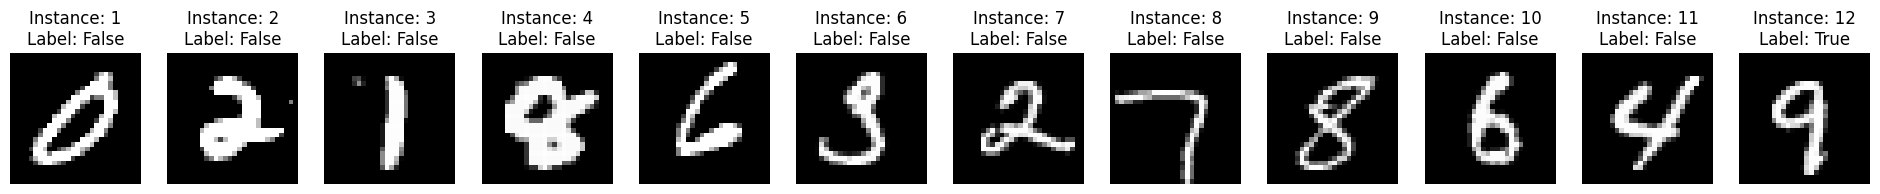

In [4]:
bag, label = next(iter(train_loader))

bag = bag.squeeze(0)

# Extract the bag_label and instance_labels for this batch
bag_label = label[0][0]
instance_labels = label[1][0]

# Pass them as a list to match the visualize_bag expected signature
visualize_bag(bag, [bag_label, instance_labels])

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class Attention(nn.Module):
    def __init__(self):
        super(Attention, self).__init__()
        self.M = 500
        self.L = 128
        self.ATTENTION_BRANCHES = 1

        self.feature_extractor_part1 = nn.Sequential(
            nn.Conv2d(1, 20, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool2d(2, stride=2),
            nn.Conv2d(20, 50, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool2d(2, stride=2)
        )

        self.feature_extractor_part2 = nn.Sequential(
            nn.Linear(50 * 4 * 4, self.M),
            nn.ReLU(),
        )

        self.attention = nn.Sequential(
            nn.Linear(self.M, self.L), # matrix V
            nn.Tanh(),
            nn.Linear(self.L, self.ATTENTION_BRANCHES) # matrix w (or vector w if self.ATTENTION_BRANCHES==1)
        )

        self.classifier = nn.Sequential(
            nn.Linear(self.M*self.ATTENTION_BRANCHES, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        # Ensure we properly squeeze out redundant dimensions
        x = x.squeeze(0)
        if x.dim() == 5:
            x = x.squeeze(2) # squeezes [K, 1, 1, 28, 28] -> [K, 1, 28, 28]
        elif x.dim() == 4 and x.size(1) == 1 and x.size(2) == 1:
            x = x.squeeze(2)

        H = self.feature_extractor_part1(x)
        H = H.view(-1, 50 * 4 * 4)
        H = self.feature_extractor_part2(H)  # KxM

        A = self.attention(H)  # KxATTENTION_BRANCHES
        A = torch.transpose(A, 1, 0)  # ATTENTION_BRANCHESxK
        A = F.softmax(A, dim=1)  # softmax over K

        Z = torch.mm(A, H)  # ATTENTION_BRANCHESxM

        Y_prob = self.classifier(Z)
        Y_hat = torch.ge(Y_prob, 0.5).float()

        return Y_prob, Y_hat, A

    # AUXILIARY METHODS
    def calculate_classification_error(self, X, Y):
        Y = Y.float()
        _, Y_hat, _ = self.forward(X)
        error = 1. - Y_hat.eq(Y).cpu().float().mean().data.item()

        return error, Y_hat

    def calculate_objective(self, X, Y):
        Y = Y.float()
        Y_prob, _, A = self.forward(X)
        Y_prob = torch.clamp(Y_prob, min=1e-5, max=1. - 1e-5)
        neg_log_likelihood = -1. * (Y * torch.log(Y_prob) + (1. - Y) * torch.log(1. - Y_prob))  # negative log bernoulli

        return neg_log_likelihood, A

In [6]:
epochs = 20
learning_rate = 0.0005
weight_decay = 0.0001
seed = 1

torch.manual_seed(seed)

device = torch.device('cuda' if torch.cuda.is_available()else 'cpu')
print('Device:', device)

Device: cpu


In [7]:
train_loader = data_utils.DataLoader(
    MnistBags(num_bag=25, seed=seed, train=True),
    batch_size=1,
    shuffle = True
)


test_loader = data_utils.DataLoader(
    MnistBags(num_bag=200, seed=seed, train=False),
    batch_size=1,
    shuffle=False
)

In [8]:
import torch.optim as optim

In [9]:
model = Attention().to(device)

optimizer = optim.Adam(
     model.parameters(),
     lr = learning_rate,
     weight_decay=weight_decay
)

In [10]:
import torch
import torch.optim as optim
from torch.utils.data import DataLoader

# Training configuration
epochs = 20
learning_rate = 0.0005
weight_decay = 0.0001
seed = 1

torch.manual_seed(seed)

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


# 1. Load training and testing datasets
train_loader = DataLoader(
    MnistBags(num_bag=25, seed=seed, train=True),
    batch_size=1,
    shuffle=True
)

test_loader = DataLoader(
    MnistBags(num_bag=200, seed=seed, train=False),
    batch_size=1,
    shuffle=False
)


# 2. Initialize model and optimizer
model = Attention().to(device)

optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
)


# 3. Training function
def train(epoch):

    model.train()

    total_loss = 0
    total_error = 0

    for data, label in train_loader:

        data = data.to(device)
        bag_label = label[0].to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Calculate loss
        loss, _ = model.calculate_objective(data, bag_label)

        # Calculate classification error
        error, _ = model.calculate_classification_error(data, bag_label)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        total_loss += loss.item()
        total_error += error  # Removed .item() since error is already a float

    # Calculate average loss and error
    avg_loss = total_loss / len(train_loader)
    avg_error = total_error / len(train_loader)

    print(f"Epoch {epoch}: Loss = {avg_loss:.4f}, Error = {avg_error:.4f}")


# 4. Testing function
def test():

    model.eval()

    total_loss = 0
    total_error = 0

    with torch.no_grad():

        for data, label in test_loader:

            data = data.to(device)
            bag_label = label[0].to(device)

            # Evaluate the model
            loss, attention_weights = model.calculate_objective(data, bag_label)

            error, predicted_label = model.calculate_classification_error(
                data, bag_label
            )

            total_loss += loss.item()
            total_error += error  # Removed .item() since error is already a float

    avg_loss = total_loss / len(test_loader)
    avg_error = total_error / len(test_loader)

    print(f"Test Loss: {avg_loss:.4f}")
    print(f"Test Error: {avg_error:.4f}")


# 5. Run training and testing
trying_epochs = epochs
for epoch in range(1, trying_epochs + 1):
    train(epoch)

print("\nTraining complete. Evaluating model...")
test()

Using device: cpu
Epoch 1: Loss = 0.7259, Error = 0.5600
Epoch 2: Loss = 0.6921, Error = 0.4800
Epoch 3: Loss = 0.6859, Error = 0.4800
Epoch 4: Loss = 0.6425, Error = 0.2400
Epoch 5: Loss = 0.5055, Error = 0.2000
Epoch 6: Loss = 0.2881, Error = 0.1200
Epoch 7: Loss = 0.3287, Error = 0.2000
Epoch 8: Loss = 0.1539, Error = 0.0400
Epoch 9: Loss = 0.0310, Error = 0.0000
Epoch 10: Loss = 0.0058, Error = 0.0000
Epoch 11: Loss = 0.0030, Error = 0.0000
Epoch 12: Loss = 0.0020, Error = 0.0000
Epoch 13: Loss = 0.0014, Error = 0.0000
Epoch 14: Loss = 0.0011, Error = 0.0000
Epoch 15: Loss = 0.0009, Error = 0.0000
Epoch 16: Loss = 0.0007, Error = 0.0000
Epoch 17: Loss = 0.0006, Error = 0.0000
Epoch 18: Loss = 0.0005, Error = 0.0000
Epoch 19: Loss = 0.0004, Error = 0.0000
Epoch 20: Loss = 0.0003, Error = 0.0000

Training complete. Evaluating model...
Test Loss: 1.5398
Test Error: 0.3150


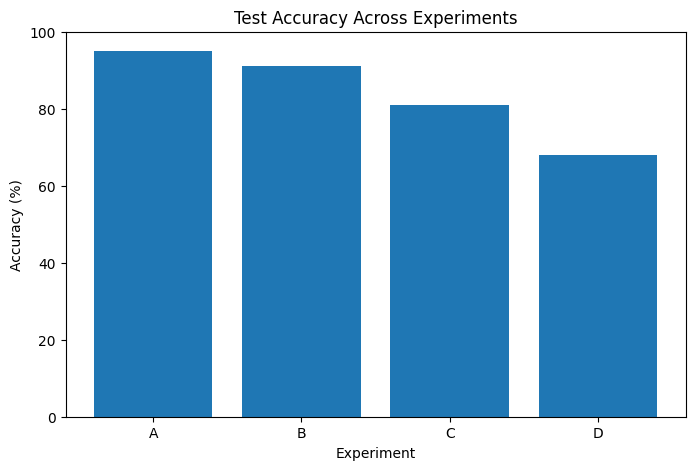

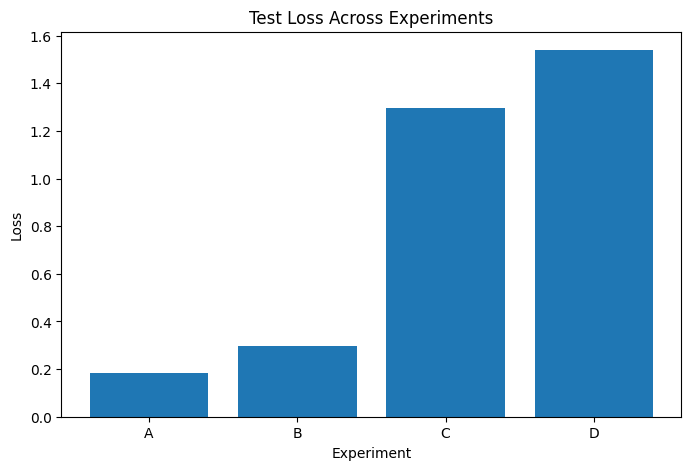

In [12]:
import matplotlib.pyplot as plt

experiments = ['A', 'B', 'C', 'D']
test_accuracy = [95, 91, 81, 68]
test_loss = [0.1857, 0.2961, 1.2957, 1.5398]

# Test Accuracy
plt.figure(figsize=(8, 5))

plt.bar(experiments, test_accuracy)

plt.title('Test Accuracy Across Experiments')
plt.xlabel('Experiment')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)

plt.show()


# Test Loss
plt.figure(figsize=(8, 5))

plt.bar(experiments, test_loss)

plt.title('Test Loss Across Experiments')
plt.xlabel('Experiment')
plt.ylabel('Loss')

plt.show()